<a href="https://colab.research.google.com/github/harinis8122006/Google-Collab/blob/main/household_power_consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf

print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Libraries ready!")


Pandas: 2.2.3
TensorFlow: 2.21.0
Libraries ready!


In [2]:
file_path = "/content/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Original dataset shape: (2075259, 9)
Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)

df = df.dropna(
    subset=["Datetime", "Global_active_power"]
).sort_values("Datetime").reset_index(drop=True)

# Split wherever minute-level continuity breaks
breaks = df["Datetime"].diff() != pd.Timedelta(minutes=1)
groups = breaks.cumsum()

df["group"] = groups

segment = None

for _, part in df.groupby("group"):
    if len(part) >= 10000:
        segment = part.iloc[:10000].copy()
        break

if segment is not None:
    print("Found 10,000 consecutive valid records!")
    print("Start:", segment["Datetime"].iloc[0])
    print("End:", segment["Datetime"].iloc[-1])
    print("Records:", len(segment))
else:
    print("No 10,000-record continuous segment found.")


Found 10,000 consecutive valid records!
Start: 2006-12-21 11:25:00
End: 2006-12-28 10:04:00
Records: 10000


In [4]:
segment = segment[["Datetime", "Global_active_power"]].copy()

segment.to_csv(
    "electricity_10000_consecutive.csv",
    index=False
)

print("Dataset saved successfully!")
print("Shape:", segment.shape)
display(segment.head())


Dataset saved successfully!
Shape: (10000, 2)


,Datetime,Global_active_power
6839,2006-12-21 11:25:00,0.246
6840,2006-12-21 11:26:00,0.246
6841,2006-12-21 11:27:00,0.244
6842,2006-12-21 11:28:00,0.244
6843,2006-12-21 11:29:00,0.244


In [5]:

from sklearn.preprocessing import MinMaxScaler

data = segment[["Global_active_power"]].values.astype("float32")

split = int(len(data) * 0.8)

scaler = MinMaxScaler()
scaler.fit(data[:split])

scaled_data = scaler.transform(data)

print("Normalized shape:", scaled_data.shape)
print("Minimum:", scaled_data.min())
print("Maximum:", scaled_data.max())


Normalized shape: (10000, 1)
Minimum: 0.0
Maximum: 1.0


In [6]:
import numpy as np

window = 60
X, y = [], []

for i in range(window, len(scaled_data)):
    X.append(scaled_data[i-window:i])
    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)

split_seq = int(len(X) * 0.8)

X_train, X_test = X[:split_seq], X[split_seq:]
y_train, y_test = y[:split_seq], y[split_seq:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (7952, 60, 1)
X_test: (1988, 60, 1)


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    tf.keras.Input(shape=(60, 1)),
    SimpleRNN(32, activation="tanh"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 0.0129 - mae: 0.0780 - val_loss: 0.0017 - val_mae: 0.0252
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0077 - mae: 0.0588 - val_loss: 0.0016 - val_mae: 0.0263
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0065 - mae: 0.0533 - val_loss: 0.0014 - val_mae: 0.0223
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0061 - mae: 0.0510 - val_loss: 0.0014 - val_mae: 0.0225
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0056 - mae: 0.0482 - val_loss: 0.0014 - val_mae: 0.0220
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0053 - mae: 0.0470 - val_loss: 0.0013 - val_mae: 0.0216
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0054 - mae: 0.0473 - val_loss: 0.0012 - val_mae: 0.0195
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0052 - mae: 0.0458 - val_loss: 0.0013 - val_mae: 0.0201
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - l

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred_scaled = model.predict(X_test)

y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)
y_predicted = scaler.inverse_transform(pred_scaled)

mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
MAE: 0.1308 kW
RMSE: 0.2561 kW


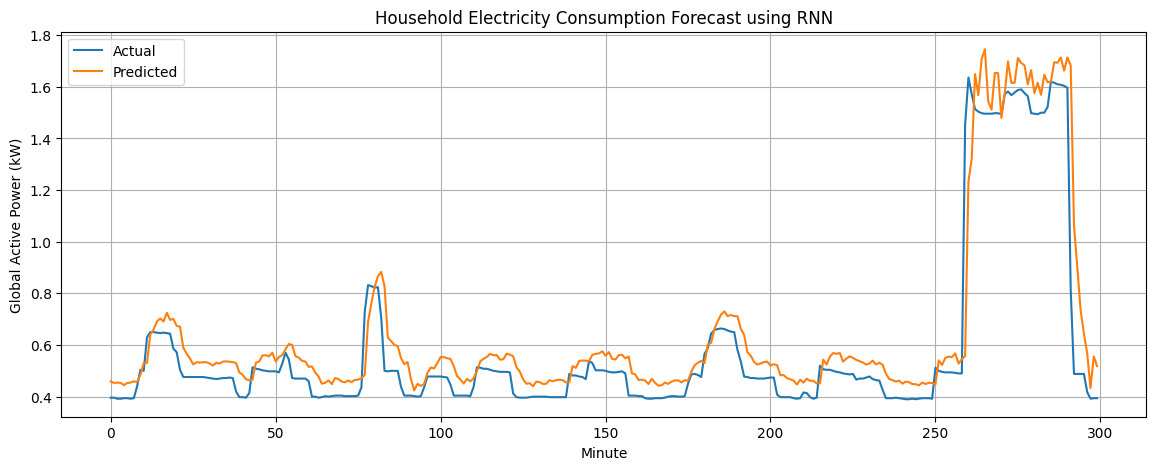

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_actual[:300], label="Actual")
plt.plot(y_predicted[:300], label="Predicted")
plt.title("Household Electricity Consumption Forecast using RNN")
plt.xlabel("Minute")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
# Save trained model
model.save("household_electricity_rnn.keras")

# Save prediction results
results = pd.DataFrame({
    "Actual_kW": y_actual.flatten(),
    "Predicted_kW": y_predicted.flatten()
})
results.to_csv("rnn_predictions.csv", index=False)

# Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Value_kW": [mae, rmse]
})
metrics.to_csv("rnn_metrics.csv", index=False)

print("Final model and results saved!")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")


Final model and results saved!
MAE: 0.1308 kW
RMSE: 0.2561 kW


In [12]:

import numpy as np
import pandas as pd

# Enter the last 60 minutes of electricity readings (kW)
print("Enter 60 readings separated by commas:")

user_input = input()

readings = np.array(
    [float(x.strip()) for x in user_input.split(",")],
    dtype=np.float32
)

if len(readings) != 60:
    print("Please enter exactly 60 readings.")
elif np.any(readings < 0):
    print("Readings must be non-negative.")
else:
    input_scaled = scaler.transform(
        readings.reshape(-1, 1)
    ).reshape(1, 60, 1)

    prediction_scaled = model.predict(
        input_scaled, verbose=0
    )

    prediction = scaler.inverse_transform(
        prediction_scaled
    )[0, 0]

    print(f"Predicted next-minute consumption: {prediction:.3f} kW")


Enter 60 readings separated by commas:
4.216, 5.360, 5.374, 5.388, 3.666, 3.520, 3.702, 3.700, 3.668, 3.662, 4.448, 5.412, 5.224, 5.268, 4.054, 3.384, 3.270, 3.430, 3.266, 3.728, 5.894, 7.706, 7.026, 5.174, 4.474, 3.248, 3.236, 3.228, 3.258, 3.178, 2.720, 3.758, 4.342, 4.512, 4.058, 2.472, 2.790, 2.624, 2.772, 3.740, 4.928, 6.052, 6.752, 6.474, 6.308, 4.464, 3.396, 3.090, 3.730, 2.308, 2.388, 4.598, 4.524, 4.202, 4.472, 2.852, 2.928, 2.940, 2.934, 2.926
Predicted next-minute consumption: 3.159 kW


In [13]:
# Use 60 actual readings from the test dataset
sample = data[-60:].reshape(-1, 1)

input_scaled = scaler.transform(sample).reshape(1, 60, 1)

pred_scaled = model.predict(input_scaled, verbose=0)
prediction = scaler.inverse_transform(pred_scaled)[0, 0]

print("Last 60 readings used:", len(sample))
print(f"Predicted next-minute consumption: {prediction:.3f} kW")


Last 60 readings used: 60
Predicted next-minute consumption: 0.387 kW


SIMULATED REAL-TIME RNN DASHBOARD
--------------------------------
Simulated minute: 20 of 20
Actual reading:    0.394 kW
RNN prediction:    0.459 kW
Absolute error:    0.065 kW

Actual vs Predicted Consumption


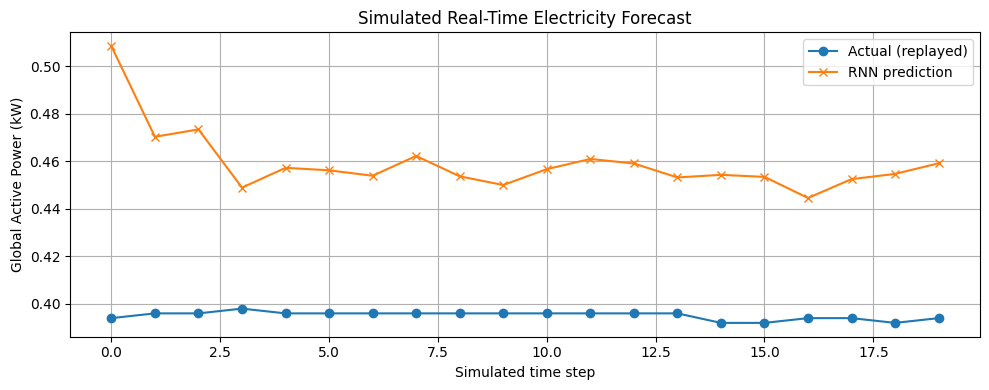

Simulation completed!


In [14]:

import numpy as np
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output, display

# Use the selected 10,000 historical readings
raw_data = segment["Global_active_power"].values.reshape(-1, 1).astype("float32")

# Begin with the unseen test portion
start = int(len(raw_data) * 0.8)
actual_values = []
predicted_values = []

print("Starting simulated real-time electricity forecasting...")

# Replay 20 unseen readings, one every 2 seconds
for i in range(start, min(start + 20, len(raw_data))):

    # Previous 60 minutes of readings
    recent = raw_data[i-60:i]

    # Normalize and predict next-minute consumption
    x = scaler.transform(recent).reshape(1, 60, 1)
    pred_scaled = model.predict(x, verbose=0)
    prediction = scaler.inverse_transform(pred_scaled)[0, 0]

    # Historical unseen reading used as simulated live input
    actual = float(raw_data[i, 0])

    actual_values.append(actual)
    predicted_values.append(float(prediction))

    clear_output(wait=True)

    print("SIMULATED REAL-TIME RNN DASHBOARD")
    print("--------------------------------")
    print("Simulated minute:", len(actual_values), "of 20")
    print(f"Actual reading:    {actual:.3f} kW")
    print(f"RNN prediction:    {prediction:.3f} kW")
    print(f"Absolute error:    {abs(actual - prediction):.3f} kW")
    print("\nActual vs Predicted Consumption")

    plt.figure(figsize=(10, 4))
    plt.plot(actual_values, marker="o", label="Actual (replayed)")
    plt.plot(predicted_values, marker="x", label="RNN prediction")
    plt.xlabel("Simulated time step")
    plt.ylabel("Global Active Power (kW)")
    plt.title("Simulated Real-Time Electricity Forecast")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    display(plt.gcf())
    plt.close()

    time.sleep(2)

print("Simulation completed!")


In [15]:
plt.savefig("rnn_realtime_simulation.png", dpi=300)

<Figure size 640x480 with 0 Axes>